# Activation patching: which components carry the bias in Qwen3.5-9B, and what SFT changed

**Question.** When only the protected attribute in a CV changes, which layers, heads and MLPs carry that change into the hire/reject decision? And what does the SFT debiasing change in that pathway?

**Setup.**
- **Models:** base Qwen3.5-9B and the published SFT adapter (English).
- **Contrasts:** three, fixed in advance from the audit: Combat vs Civilian (implicit and explicit), and Atheist vs Christian (implicit).
- **Pairs:** 64 per run, each with a base-model effect ≥ 0.5 logits.
- **Discovery and confirmation:** circuits are discovered on training-pool CVs (base model) and confirmed on the benchmark.
- **SFT comparison:** base and SFT are compared on the *same* benchmark pairs.
- **Scale:** 9 runs, about 150,000 patched forward passes.

### Key findings
1. **A narrow bottleneck in depth.** In every contrast, explicit or implicit, the attribute's effect reaches the decision tokens **between layers 15 and 20**. Before layer 15 the decision tokens carry at most a quarter of it; by layer 20, more than 90%.
2. **Full-attention layer 15 is the hub.** Patching its output alone removes **73%** of the Combat-vs-Civilian (implicit) effect (95% CI 63–83%), 50% of the explicit one and 39% of the religion one. Inside it, **one head, L15.H11, removes 43% by itself** (real patching, CI 36–50%). It is a top-2 head in every contrast.
3. **The circuit has four roles:**
   - **Early readers:** attention layers 7 and 11 and GDN layers 9–14 pull the attribute into the CV and instruction tokens.
   - **Movers:** attention heads L15.H11, L15.H1, L15.H8 and L19.H11, plus GDN L17.H0, carry it to the decision tokens.
   - **Readout:** the final MLP (layer 31, 39–48%) and late attention heads (L27.H5, L31.H14) turn it into hire − reject.
   - **Opposers:** heads L15.H5, L17.H20, L23.H14 and L31.H15 push *against* the bias in every contrast.
4. **Shared core, contrast-specific edges.** Military and religion share about half of their top-20 heads. Religion leans more on L19.H11, combat on L15.H11.
5. **Robust.**
   - The circuit discovered on the pool replicates on the benchmark: component profiles correlate at r = 0.96–0.97, and 15–17 of the top-20 heads are identical.
   - AtP rankings agree with real patching (Spearman 0.94–0.99).
   - Random control heads remove close to nothing.
6. **SFT turns the same circuit down; it does not rewire it.**
   - On identical benchmark pairs, the attribute effect falls by **69–74%**.
   - The *same* components carry what remains (component profiles base vs SFT: r = 0.83–0.84), and the decision tokens still receive it at layers 15–20.
   - **The largest cuts are at the movers:** on Combat vs Civilian (implicit), L15.H11 loses 89% of its contribution (0.81 → 0.09 logits per pair), and attention layers 11 and 15 lose 85% and 81%.
   - GDN mixers, the only token mixers SFT's LoRA does not modify, keep the most of their contribution (33–54%).

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from IPython.display import display

REPO = Path.cwd().parents[1] if Path.cwd().name == "interp" else Path.cwd()
PATCH = REPO / "reports" / "interp" / "patching"
FIG = REPO / "reports" / "interp" / "figures" / "patching"
FIG.mkdir(parents=True, exist_ok=True)

SPEC_COLOR = {"base": "#2a78d6", "sft": "#eb6834", "dpo": "#1baf7a"}
SPEC_LABEL = {"base": "Base", "sft": "SFT", "dpo": "DPO"}
# Component types are a different entity from model specs, so they get later palette slots.
TYPE_COLOR = {"attention": "#6250d6", "GDN": "#eda100", "MLP": "#e87ba4"}
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110,
})
FULL_ATTN = set(range(3, 32, 4))  # layers 3, 7, ..., 31
CONTRAST = {"mil_combat_civ_impl": "Combat vs Civilian · implicit",
            "mil_combat_civ_expl": "Combat vs Civilian · explicit",
            "rel_atheist_christian_impl": "Atheist vs Christian · implicit"}

def run(spec, dataset, contrast):
    d = PATCH / f"{spec}-{dataset}-{contrast}-n64-s42"
    if not (d / "real.csv").exists():
        return None
    out = {name: pd.read_csv(d / f"{name}.csv") for name in ("pairs", "real", "atp", "verify")
           if (d / f"{name}.csv").exists()}
    return out

def ctype(kind, layer):
    if kind == "mlp":
        return "MLP"
    return "attention" if layer in FULL_ATTN else "GDN"

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=180, bbox_inches="tight")

def table(df, digits=2):
    display(df.round(digits))

RUNS = {(s, d, c): run(s, d, c) for s in ("base", "sft") for d in ("pool", "grid") for c in CONTRAST}
RUNS = {k: v for k, v in RUNS.items() if v is not None}
pd.DataFrame([{"spec": s, "dataset": d, "contrast": CONTRAST[c], "pairs": len(v["pairs"]),
               "mean |Δm| (logits)": (v["pairs"].m_a - v["pairs"].m_b).abs().mean()}
              for (s, d, c), v in RUNS.items()]).round(2)

,spec,dataset,contrast,pairs,mean |Δm| (logits)
0,base,pool,Combat vs Civilian · implicit,64,1.31
1,base,pool,Combat vs Civilian · explicit,64,1.11
2,base,pool,Atheist vs Christian · implicit,64,1.39
3,base,grid,Combat vs Civilian · implicit,64,1.33
4,base,grid,Combat vs Civilian · explicit,64,1.50
5,base,grid,Atheist vs Christian · implicit,64,1.32
6,sft,grid,Combat vs Civilian · implicit,64,0.34
7,sft,grid,Combat vs Civilian · explicit,64,0.46
8,sft,grid,Atheist vs Christian · implicit,64,0.41


## How to read the numbers

- **A contrast pair** is two prompts identical except for the attribute: **A** (e.g. *Participant in combat actions*) and **B** (*Civilian*). The attribute effect is Δm = margin(A) − margin(B), where the margin is the fp32 logit gap hire − reject at the decision token.
- **A patch** reruns A with one activation replaced by B's at the matching positions. Every patched position lies *after* the attribute, where A and B are identical text. That is what makes the positions comparable.
- **Share removed** = how much of the pair's attribute effect the patch takes away. 1 means "patching this alone turns A into B", 0 means no effect, and a negative value means the component *opposes* the bias. Each pair is oriented by the sign of its own effect, so pairs pushed up and pairs pushed down both count (the *sensitivity* metric). The share is a ratio of sums over pairs, and the 95% CI is a bootstrap over candidates.
- **Single-component shares do not add up to 1.** Components act in series: if attention layer 15 removes 73% and MLP 31 removes 43%, then removing either one breaks most of the path.
- **AtP** (attribution patching) is a gradient estimate of every head's effect from one backward pass. It is used to rank all 896 heads. The top 24 per position set, plus 8 random heads, are then re-measured by real patching. Head numbers shown are real patching wherever it was run.
- **Not measured here:** effects at the attribute tokens themselves. Different attributes have different token lengths, so those positions cannot be compared one-to-one.

## 1 · Where in depth the attribute's influence lives

The residual stream entering layer L is replaced by the other variant's, either on **all tokens after the attribute** (solid line) or only on the **last ~12 tokens** (the chat template's close plus `{"decision": "`; dashed line). Each curve shows how much of the effect has reached those tokens by that depth.

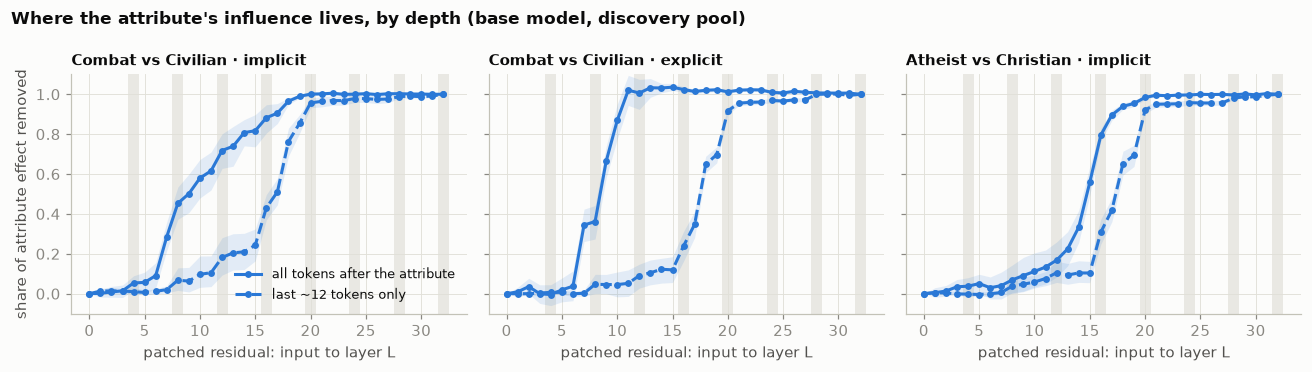

grey bands: each full-attention layer (its output first appears in the next layer's input)


In [2]:
def resid_curve(r, cls):
    x = r["real"]; x = x[x.kind.isin(["resid_pre", "final_prenorm"]) & (x.cls == cls)].copy()
    x["depth"] = np.where(x.kind == "final_prenorm", 32, x.layer)  # input to layer L; 32 = after the last layer
    return x.sort_values("depth")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, c in zip(axes, CONTRAST):
    r = RUNS.get(("base", "pool", c))
    if r is None:
        ax.set_visible(False); continue
    for x in FULL_ATTN:
        ax.axvspan(x + 0.5, x + 1.5, color=GRID, alpha=0.7, lw=0, zorder=0)
    for cls, style, lab in (("suffix", "-", "all tokens after the attribute"), ("late", "--", "last ~12 tokens only")):
        d = resid_curve(r, cls)
        ax.plot(d.depth, d.share_removed, color=SPEC_COLOR["base"], linestyle=style, marker="o", markersize=3.5, label=lab)
        ax.fill_between(d.depth, d.ci_low, d.ci_high, color=SPEC_COLOR["base"], alpha=0.12, lw=0)
    ax.set_title(CONTRAST[c], fontsize=10); ax.set_xlabel("patched residual: input to layer L")
    ax.set_ylim(-0.1, 1.1)
axes[0].set_ylabel("share of attribute effect removed"); axes[0].legend(loc="lower right", fontsize=8.5)
fig.suptitle("Where the attribute's influence lives, by depth (base model, discovery pool)", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "residual_sweep"); plt.show()
print("grey bands: each full-attention layer (its output first appears in the next layer's input)")

**Reading it:**

- **The solid curve shows the attribute spreading into the CV and instruction tokens.** An implicit sentence spreads gradually, over layers 6–18. An explicit label ("Candidate's military status: …") is read in one jump at layers 7–10.
- **The dashed curve shows when it reaches the decision tokens.** In all three contrasts it stays below ~25% until layer 15, then climbs to more than 90% by layer 20. **Layers 15–19 are the bottleneck**, whatever the attribute and however it is stated.
- **After layer 20, nothing more needs to be read from earlier tokens.** The rest of the decision is computed at the decision tokens themselves.

## 2 · Which mixers and MLPs carry it

Each bar patches *one* component's output (a layer's token mixer, either attention or GDN, or its MLP) on every token after the attribute.

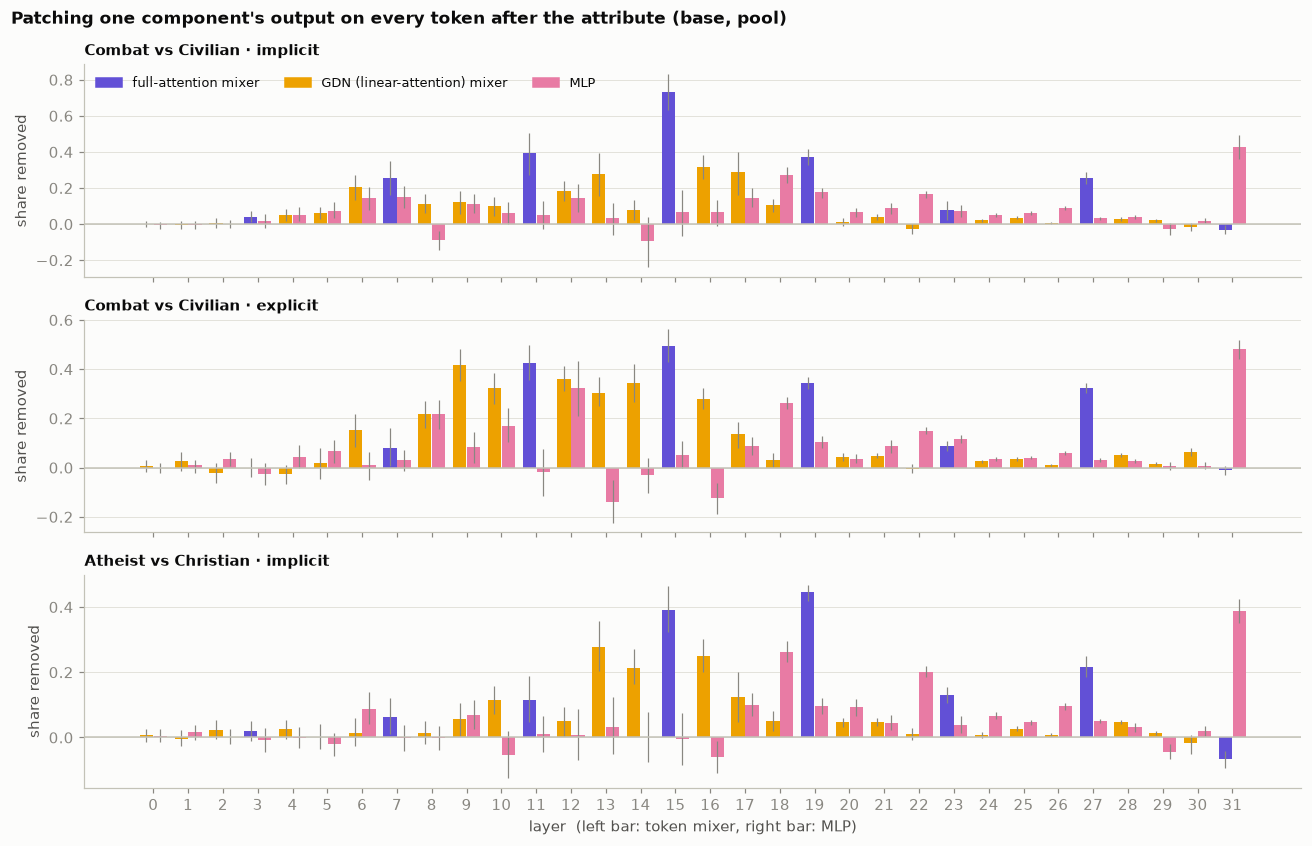

component  share removed  \
contrast                        positions                                 
Combat vs Civilian · implicit   suffix     attention L15           0.73   
                                suffix           MLP L31           0.43   
                                suffix     attention L11           0.39   
                                suffix     attention L19           0.37   
                                suffix           GDN L16           0.31   
                                suffix           GDN L17           0.29   
                                suffix           GDN L13           0.28   
                                suffix           MLP L18           0.27   
Combat vs Civilian · explicit   suffix     attention L15           0.50   
                                suffix           MLP L31           0.48   
                                suffix     attention L11           0.43   
                                suffix            GDN L9           0.42   
                                suffix           GDN L12           0.36   
                                suffix           GDN L14           0.35   
                                suffix     attention L19           0.34   
                                suffix     attention L27           0.32   
Atheist vs Christian · implicit suffix     attention L19           0.44   
                                suffix     attention L15           0.39   
                                suffix           MLP L31           0.39   
                                suffix           GDN L13           0.28   
                                suffix           MLP L18           0.26   
                                suffix           GDN L16           0.25   
                                suffix     attention L27           0.22   
                                suffix           GDN L14           0.21   

                                                 95% CI  
contrast                        positions                
Combat vs Civilian · implicit   suffix     [0.63, 0.83]  
                                suffix     [0.36, 0.50]  
                                suffix     [0.27, 0.51]  
                                suffix     [0.33, 0.42]  
                                suffix     [0.25, 0.38]  
                                suffix     [0.16, 0.40]  
                                suffix     [0.16, 0.40]  
                                suffix     [0.23, 0.32]  
Combat vs Civilian · explicit   suffix     [0.43, 0.56]  
                                suffix     [0.44, 0.52]  
                                suffix     [0.36, 0.50]  
                                suffix     [0.35, 0.48]  
                                suffix     [0.31, 0.41]  
                                suffix     [0.27, 0.42]  
                                suffix     [0.32, 0.37]  
                                suffix     [0.30, 0.35]  
Atheist vs Christian · implicit suffix     [0.42, 0.47]  
                                suffix     [0.32, 0.46]  
                                suffix     [0.35, 0.43]  
                                suffix     [0.20, 0.36]  
                                suffix     [0.23, 0.29]  
                                suffix     [0.20, 0.30]  
                                suffix     [0.19, 0.25]  
                                suffix     [0.16, 0.27]

In [3]:
def components(r, cls="suffix"):
    x = r["real"]; x = x[x.kind.isin(["mixer", "mlp"]) & (x.cls == cls)].copy()
    x["type"] = [ctype(k, l) for k, l in zip(x.kind, x.layer)]
    return x

fig, axes = plt.subplots(len(CONTRAST), 1, figsize=(12, 2.6 * len(CONTRAST)), sharex=True)
for ax, c in zip(np.atleast_1d(axes), CONTRAST):
    r = RUNS.get(("base", "pool", c))
    if r is None:
        ax.set_visible(False); continue
    x = components(r)
    for i, (kind, off) in enumerate((("mixer", -0.2), ("mlp", 0.2))):
        d = x[x.kind == kind].sort_values("layer")
        ax.bar(d.layer + off, d.share_removed, width=0.38, color=[TYPE_COLOR[t] for t in d.type],
               yerr=[d.share_removed - d.ci_low, d.ci_high - d.share_removed], ecolor=MUTED, error_kw={"lw": 0.8})
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title(CONTRAST[c], fontsize=10); ax.set_ylabel("share removed")
    ax.grid(axis="x", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in TYPE_COLOR.values()]
np.atleast_1d(axes)[0].legend(handles, ["full-attention mixer", "GDN (linear-attention) mixer", "MLP"], ncol=3, loc="upper left", fontsize=8.5)
np.atleast_1d(axes)[-1].set_xlabel("layer  (left bar: token mixer, right bar: MLP)")
np.atleast_1d(axes)[-1].set_xticks(range(32))
fig.suptitle("Patching one component's output on every token after the attribute (base, pool)", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "component_sweep"); plt.show()

rows = []
for c in CONTRAST:
    r = RUNS.get(("base", "pool", c))
    if r is None: continue
    for cls in ("suffix", "late"):
        x = components(r, cls).sort_values("share_removed", ascending=False).head(8)
        rows += [{"contrast": CONTRAST[c], "positions": cls, "component": f"{t} L{l}" if k == "mixer" else f"MLP L{l}",
                  "share removed": s, "95% CI": f"[{lo:.2f}, {hi:.2f}]"} for k, l, t, s, lo, hi in
                 zip(x.kind, x.layer, x.type, x.share_removed, x.ci_low, x.ci_high)]
top_components = pd.DataFrame(rows)
display(top_components[top_components.positions == "suffix"].round(2).set_index(["contrast", "positions"]))

**Reading it:**

| Contrast | Largest components (share removed) |
|---|---|
| Combat vs Civilian · implicit | **attention 15 (0.73)**, MLP 31 (0.43), attention 11 (0.39), attention 19 (0.37), GDN 16 (0.31) |
| Combat vs Civilian · explicit | **attention 15 (0.50)**, MLP 31 (0.48), attention 11 (0.43), GDN 9 (0.42), GDN 12 (0.36) |
| Atheist vs Christian · implicit | **attention 19 (0.44)**, attention 15 (0.39), MLP 31 (0.39), GDN 13 (0.28) |

- **Four of the 8 full-attention layers (11, 15, 19, 27) do most of the cross-token moving.** The GDN layers in between (9–17) form a supporting band.
- **The explicit label leans on early GDN layers (9, 12, 14).** This fits a labelled field being picked up locally before attention moves it.
- **MLP 31, the last MLP, matters in every contrast (39–48%).** It acts on the decision tokens, so it is where the attribute signal is converted into the hire − reject decision.

## 3 · Which heads

The left heatmap shows AtP for every head (Combat vs Civilian, implicit). The scatter then compares AtP with real patching for the heads selected for verification.

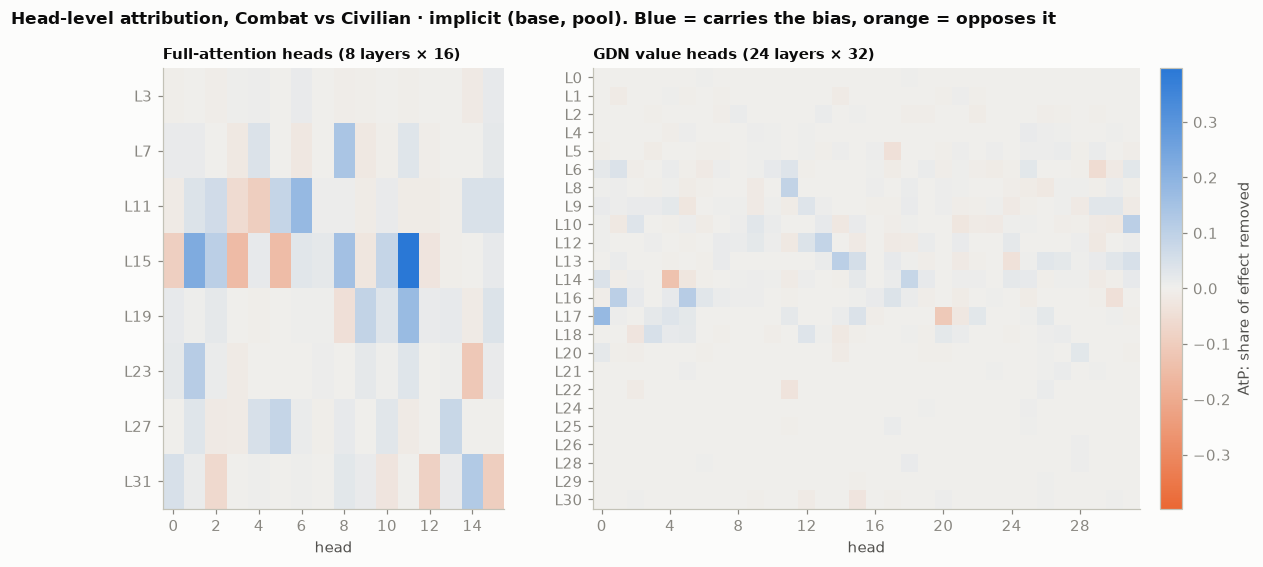

In [4]:
def head_grid(atp, cls, layers):
    h = atp[(atp.kind == "head_in") & (atp.cls == cls) & atp.layer.isin(layers)]
    return h.pivot_table(index="layer", columns="head", values="share_removed")

r = RUNS.get(("base", "pool", "mil_combat_civ_impl"))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1, 1.6]})
attn = head_grid(r["atp"], "suffix", sorted(FULL_ATTN)); gdn = head_grid(r["atp"], "suffix", [l for l in range(32) if l not in FULL_ATTN])
lim = np.nanmax(np.abs(np.concatenate([attn.values.ravel(), gdn.values.ravel()])))
for ax, g, title in ((axes[0], attn, "Full-attention heads (8 layers × 16)"), (axes[1], gdn, "GDN value heads (24 layers × 32)")):
    im = ax.imshow(g.values, cmap=DIVERGING, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
    ax.set_yticks(range(len(g.index)), [f"L{l}" for l in g.index]); ax.set_xlabel("head")
    ax.set_xticks(range(0, g.shape[1], 4 if g.shape[1] > 16 else 2))
    ax.set_title(title, fontsize=10); ax.grid(False)
cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02); cb.set_label("AtP: share of effect removed")
fig.suptitle("Head-level attribution, Combat vs Civilian · implicit (base, pool). Blue = carries the bias, orange = opposes it",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
save(fig, "head_atp_heatmap"); plt.show()

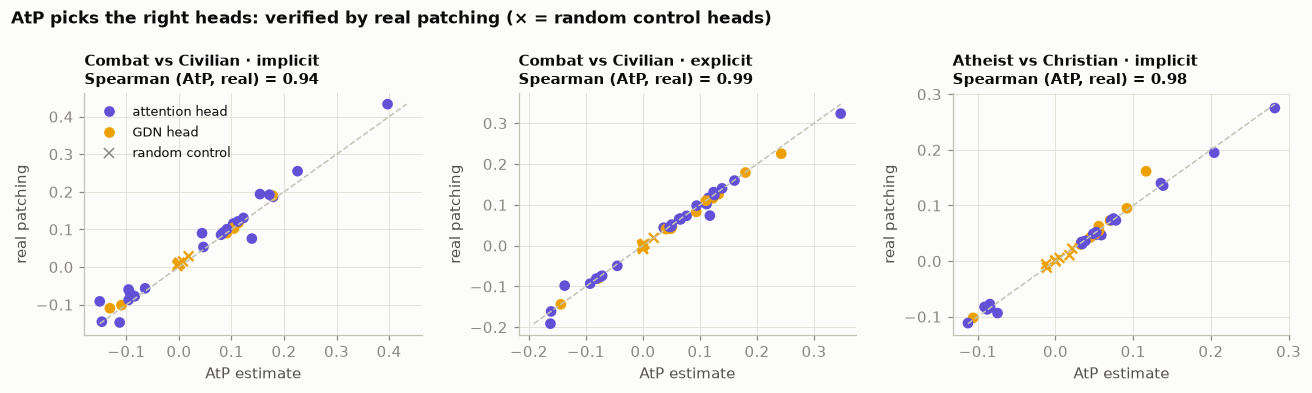

type  share removed (real)  \
contrast                        head                                         
Combat vs Civilian · implicit   A L15.H11  attention                  0.43   
                                A L15.H1   attention                  0.25   
                                A L15.H8   attention                  0.19   
                                A L19.H11  attention                  0.19   
                                G L17.H0         GDN                  0.19   
                                A L11.H6   attention                  0.19   
                                A L23.H14  attention                 -0.15   
                                A L15.H5   attention                 -0.15   
                                A L31.H14  attention                  0.13   
                                A L23.H1   attention                  0.12   
Combat vs Civilian · explicit   A L15.H11  attention                  0.32   
                                G L14.H0         GDN                  0.23   
                                A L15.H5   attention                 -0.19   
                                G L17.H0         GDN                  0.18   
                                A L11.H3   attention                 -0.16   
                                A L11.H14  attention                  0.16   
                                G L17.H20        GDN                 -0.14   
                                A L31.H14  attention                  0.14   
                                A L27.H5   attention                  0.13   
                                G L13.H14        GDN                  0.13   
Atheist vs Christian · implicit A L19.H11  attention                  0.28   
                                A L15.H11  attention                  0.19   
                                G L14.H0         GDN                  0.16   
                                A L31.H14  attention                  0.14   
                                A L23.H1   attention                  0.14   
                                A L31.H15  attention                 -0.11   
                                G L17.H20        GDN                 -0.10   
                                G L17.H0         GDN                  0.09   
                                A L23.H14  attention                 -0.09   
                                A L31.H2   attention                 -0.09   

                                                   95% CI   AtP  \
contrast                        head                              
Combat vs Civilian · implicit   A L15.H11    [0.36, 0.50]  0.40   
                                A L15.H1     [0.19, 0.31]  0.23   
                                A L15.H8     [0.15, 0.25]  0.15   
                                A L19.H11    [0.15, 0.24]  0.17   
                                G L17.H0     [0.13, 0.24]  0.18   
                                A L11.H6     [0.13, 0.25]  0.18   
                                A L23.H14  [-0.22, -0.08] -0.11   
                                A L15.H5   [-0.20, -0.10] -0.15   
                                A L31.H14    [0.11, 0.15]  0.12   
                                A L23.H1     [0.09, 0.15]  0.11   
Combat vs Civilian · explicit   A L15.H11    [0.28, 0.37]  0.35   
                                G L14.H0     [0.18, 0.27]  0.24   
                                A L15.H5   [-0.24, -0.15] -0.16   
                                G L17.H0     [0.15, 0.20]  0.18   
                                A L11.H3   [-0.21, -0.11] -0.16   
                                A L11.H14    [0.11, 0.21]  0.16   
                                G L17.H20  [-0.17, -0.12] -0.14   
                                A L31.H14    [0.13, 0.15]  0.14   
                                A L27.H5     [0.11, 0.15]  0.12   
                                G L13.H14    [0.10, 0.15]  0.13   
Atheist vs Christian · implicit A L19.H11    [0.24, 0.31]  0.28   
          

In [5]:
def verified(r, cls="suffix"):
    v = r["verify"]; v = v[v.cls == cls].copy()
    a = r["atp"]; a = a[(a.kind == "head_in") & (a.cls == cls)][["layer", "head", "share_removed"]].rename(columns={"share_removed": "atp"})
    v = v.merge(a, on=["layer", "head"])
    v["type"] = ["attention" if l in FULL_ATTN else "GDN" for l in v.layer]
    v["head_id"] = [f"{'A' if t == 'attention' else 'G'} L{l}.H{h}" for t, l, h in zip(v["type"], v["layer"], v["head"])]
    return v

fig, axes = plt.subplots(1, len(CONTRAST), figsize=(12, 3.6))
rows = []
for ax, c in zip(np.atleast_1d(axes), CONTRAST):
    r = RUNS.get(("base", "pool", c))
    if r is None or "verify" not in r:
        ax.set_visible(False); continue
    v = verified(r)
    for ctl, marker in ((False, "o"), (True, "x")):
        d = v[v.control == ctl]
        ax.scatter(d.atp, d.share_removed, c=[TYPE_COLOR[t] for t in d.type], marker=marker, s=30 if not ctl else 40, linewidths=1.5)
    lo, hi = min(v.atp.min(), v.share_removed.min()), max(v.atp.max(), v.share_removed.max())
    ax.plot([lo, hi], [lo, hi], color=AXIS, lw=1, ls="--")
    rho = v[~v.control][["atp", "share_removed"]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{CONTRAST[c]}\nSpearman (AtP, real) = {rho:.2f}", fontsize=10)
    ax.set_xlabel("AtP estimate"); ax.set_ylabel("real patching")
    for _, x in v[~v.control].sort_values("share_removed", key=abs, ascending=False).head(10).iterrows():
        rows.append({"contrast": CONTRAST[c], "head": x.head_id, "type": x.type,
                     "share removed (real)": x.share_removed, "95% CI": f"[{x.ci_low:.2f}, {x.ci_high:.2f}]",
                     "AtP": x.atp, "logits per pair": x.removed_logits_per_pair})
np.atleast_1d(axes)[0].legend([plt.Line2D([], [], marker="o", ls="", color=TYPE_COLOR["attention"]),
                               plt.Line2D([], [], marker="o", ls="", color=TYPE_COLOR["GDN"]),
                               plt.Line2D([], [], marker="x", ls="", color=MUTED)],
                              ["attention head", "GDN head", "random control"], loc="upper left", fontsize=8.5)
fig.suptitle("AtP picks the right heads: verified by real patching (× = random control heads)", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "atp_vs_real"); plt.show()
top_heads = pd.DataFrame(rows)
table(top_heads.set_index(["contrast", "head"]), 2)

**Reading it:**

- **L15.H11 is the single most important head:** 43% (implicit combat), 32% (explicit combat), 19% (religion). In religion, **L19.H11** leads with 28%.
- **Supporting carriers:** L15.H1, L15.H8, L11.H6, GDN L17.H0, L19.H11, L31.H14 and L23.H1.
- **Grouped heads:** L15.H11 and L15.H8 read the same key/value head (KV 2). They differ in their queries and output gates, which suggests a shared source being read for two purposes. Path patching can test this.
- **Opposing heads:** L15.H5, L15.H3, L17.H20, L23.H14 and L31.H15 consistently *reduce* the bias. The model partly corrects itself, and SFT could have strengthened this. Section 5 shows it did not do that much; it weakened the carriers instead.
- **AtP is reliable here:** Spearman with real patching is 0.94 (implicit combat), 0.99 (explicit) and 0.98 (religion). Random heads (×) sit at ~0.

The atlas below puts the important heads of all three contrasts side by side.

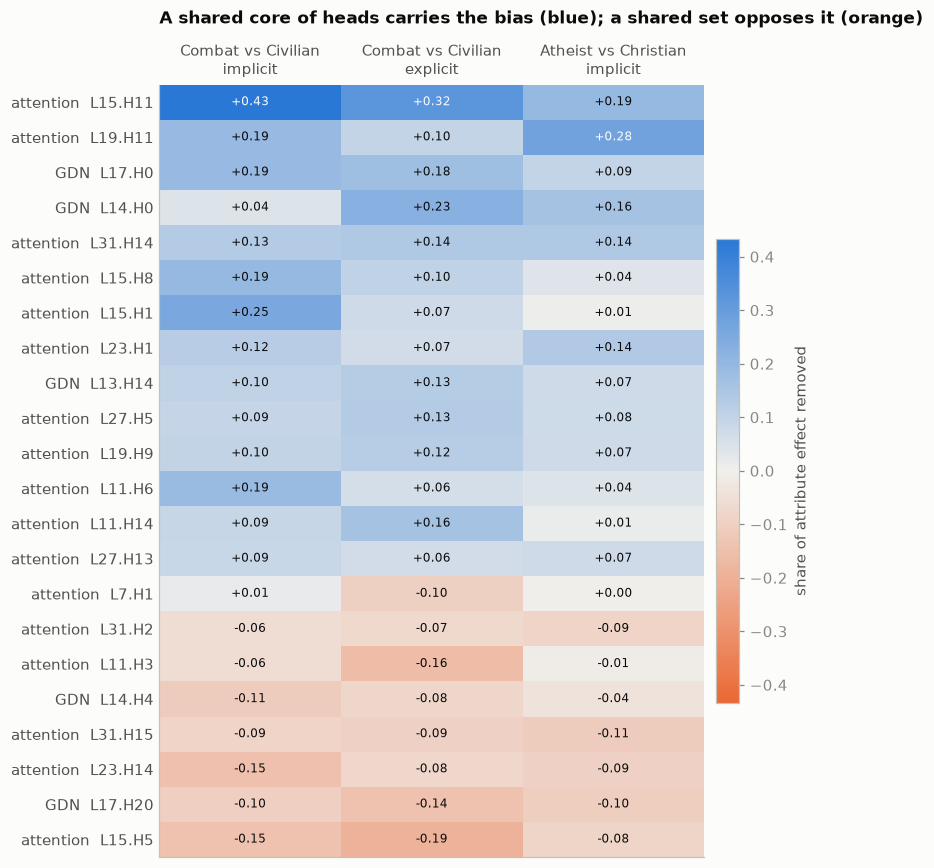

In [6]:
# One table for the circuit: every head that matters in any contrast, measured in every contrast.
def head_scores(r):
    a = r["atp"]; a = a[(a.kind == "head_in") & (a.cls == "suffix")].set_index(["layer", "head"])["share_removed"]
    if "verify" in r:  # real patching wherever it was run; AtP elsewhere (rank agreement ~0.94)
        v = r["verify"]; v = v[(v.cls == "suffix") & ~v.control].set_index(["layer", "head"])["share_removed"]
        a = a.copy(); a.loc[v.index] = v
    return a
cols = {c: head_scores(RUNS[("base", "pool", c)]) for c in CONTRAST if ("base", "pool", c) in RUNS}
atlas = pd.DataFrame(cols)
keep = sorted(set().union(*[set(atlas[c].nlargest(8).index) | set(atlas[c].nsmallest(4).index) for c in atlas]),
              key=lambda k: -atlas.loc[[k]].mean(axis=1).iloc[0])
atlas = atlas.loc[keep]
fig, ax = plt.subplots(figsize=(6.8, 0.36 * len(atlas) + 1.2))
lim = np.abs(atlas.values).max()
im = ax.imshow(atlas.values, cmap=DIVERGING, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
ax.set_yticks(range(len(atlas)), [f"{'attention' if l in FULL_ATTN else 'GDN'}  L{l}.H{h}" for l, h in atlas.index])
ax.set_xticks(range(atlas.shape[1]), [CONTRAST[c].replace(" · ", "\n") for c in atlas.columns])
ax.xaxis.tick_top(); ax.grid(False); ax.tick_params(length=0, colors=INK2)
for i in range(atlas.shape[0]):
    for j in range(atlas.shape[1]):
        val = atlas.values[i, j]
        ax.text(j, i, f"{val:+.2f}", ha="center", va="center", fontsize=8, color=INK if abs(val) < 0.6 * lim else SURFACE)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("share of attribute effect removed")
ax.set_title("A shared core of heads carries the bias (blue); a shared set opposes it (orange)", pad=40)
save(fig, "head_atlas"); plt.show()

## 4 · Does the circuit found on the training pool hold on the benchmark?

The circuit was *discovered* on job–CV pairs from the training pool, to avoid fitting it to the test set. The same experiments were then run on the benchmark.

In [7]:
rows = []
for c in CONTRAST:
    p, g = RUNS.get(("base", "pool", c)), RUNS.get(("base", "grid", c))
    if p is None or g is None: continue
    for what, kinds in (("mixers & MLPs", ["mixer", "mlp"]), ("residual", ["resid_pre", "final_prenorm"])):
        a = p["real"][p["real"].kind.isin(kinds) & (p["real"].cls == "suffix")]
        b = g["real"][g["real"].kind.isin(kinds) & (g["real"].cls == "suffix")]
        m = a.merge(b, on=["kind", "layer", "cls"], suffixes=("_pool", "_grid"))
        rows.append({"contrast": CONTRAST[c], "profile": what, "Pearson r (pool vs benchmark)": m.share_removed_pool.corr(m.share_removed_grid)})
    ha = p["atp"][(p["atp"].kind == "head_in") & (p["atp"].cls == "suffix")]
    hb = g["atp"][(g["atp"].kind == "head_in") & (g["atp"].cls == "suffix")]
    m = ha.merge(hb, on=["layer", "head", "cls"], suffixes=("_pool", "_grid"))
    top_p = set(m.nlargest(20, "share_removed_pool")[["layer", "head"]].itertuples(index=False))
    top_g = set(m.nlargest(20, "share_removed_grid")[["layer", "head"]].itertuples(index=False))
    rows.append({"contrast": CONTRAST[c], "profile": "heads (AtP, 896)", "Pearson r (pool vs benchmark)": m.share_removed_pool.corr(m.share_removed_grid),
                 "top-20 overlap": len(top_p & top_g)})
transfer = pd.DataFrame(rows)
table(transfer.set_index(["contrast", "profile"]), 2)

Pearson r (pool vs benchmark)  \
contrast                        profile                                           
Combat vs Civilian · implicit   mixers & MLPs                              0.96   
                                residual                                   1.00   
                                heads (AtP, 896)                           0.94   
Combat vs Civilian · explicit   mixers & MLPs                              0.97   
                                residual                                   1.00   
                                heads (AtP, 896)                           0.93   
Atheist vs Christian · implicit mixers & MLPs                              0.95   
                                residual                                   0.99   
                                heads (AtP, 896)                           0.89   

                                                  top-20 overlap  
contrast                        profile                           
Combat vs Civilian · implicit   mixers & MLPs                NaN  
                                residual                     NaN  
                                heads (AtP, 896)            17.0  
Combat vs Civilian · explicit   mixers & MLPs                NaN  
                                residual                     NaN  
                                heads (AtP, 896)            16.0  
Atheist vs Christian · implicit mixers & MLPs                NaN  
                                residual                     NaN  
                                heads (AtP, 896)            15.0

- **Component profiles correlate at r = 0.96–0.97** between pool and benchmark.
- **15–17 of the top-20 heads are identical.**
- The headline numbers barely move: attention 15 removes 73% on the pool vs 68% on the benchmark, and L15.H11 43% vs 49%.

The circuit is a property of the model, not of the particular CVs.

## 5 · Is it one circuit for every attribute?

In [8]:
prof = {}
for c in CONTRAST:
    r = RUNS.get(("base", "pool", c))
    if r is None: continue
    h = r["atp"][(r["atp"].kind == "head_in") & (r["atp"].cls == "suffix")].set_index(["layer", "head"])["share_removed"]
    comp = r["real"][r["real"].kind.isin(["mixer", "mlp"]) & (r["real"].cls == "suffix")].set_index(["kind", "layer"])["share_removed"]
    prof[c] = (h, comp)
rows = []
names = list(prof)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        (h1, c1), (h2, c2) = prof[names[i]], prof[names[j]]
        t1, t2 = set(h1.nlargest(20).index), set(h2.nlargest(20).index)
        rows.append({"pair": f"{CONTRAST[names[i]]}  ×  {CONTRAST[names[j]]}",
                     "components r": c1.corr(c2), "heads r": h1.corr(h2), "top-20 heads shared": len(t1 & t2)})
table(pd.DataFrame(rows).set_index("pair"), 2)

,components r,heads r,top-20 heads shared
pair,,,
Combat vs Civilian · implicit × Combat vs Civilian · explicit,0.74,0.72,10
Combat vs Civilian · implicit × Atheist vs Christian · implicit,0.81,0.69,11
Combat vs Civilian · explicit × Atheist vs Christian · implicit,0.70,0.68,9


- Across contrasts, component profiles correlate at r = 0.70–0.81 and head profiles at r = 0.68–0.72. **9–11 of the top-20 heads are shared.**
- So there is a **shared core**: the attention-15/19 movers, GDN L17.H0, the MLP-31 readout, and the opposing heads.
- Around it are **contrast-specific edges**: early GDN layers for explicit labels, and L19.H11 for religion.
- A single intervention on the core heads is therefore a plausible target for every attribute at once.

## 6 · What SFT changed

Base and SFT on the **same 64 benchmark pairs per contrast**, selected by the base model's effect. Values are in **absolute logits per pair**, because SFT's total effect is much smaller to begin with:

| Contrast | Attribute effect, base → SFT |
|---|---|
| Combat vs Civilian · implicit | 1.33 → 0.34 logits (**−74%**) |
| Combat vs Civilian · explicit | 1.50 → 0.46 (**−69%**) |
| Atheist vs Christian · implicit | 1.32 → 0.41 (**−69%**) |

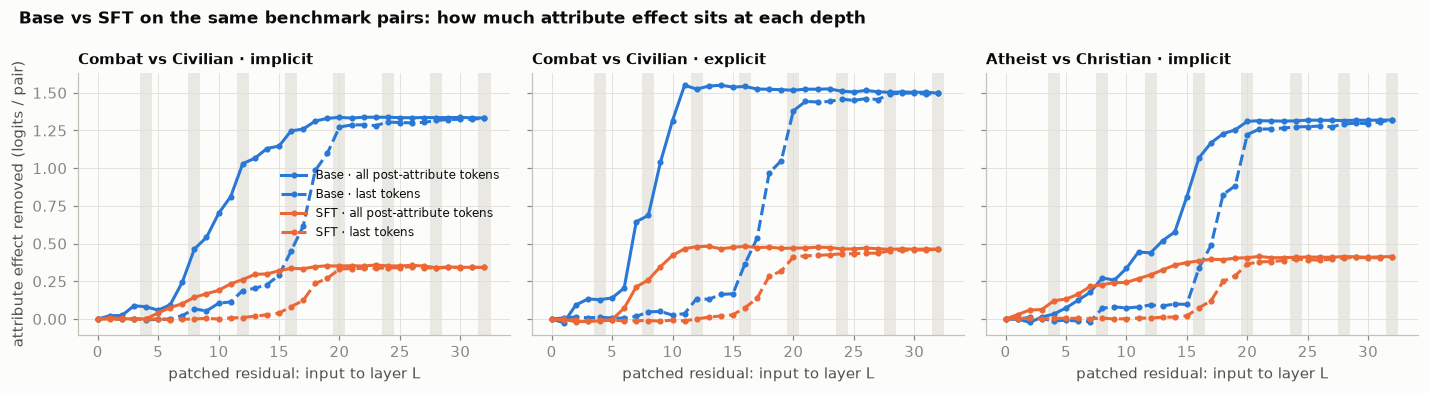

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, c in zip(axes, ["mil_combat_civ_impl", "mil_combat_civ_expl", "rel_atheist_christian_impl"]):
    for s in ("base", "sft"):
        r = RUNS.get((s, "grid", c))
        if r is None: continue
        for cls, style in (("suffix", "-"), ("late", "--")):
            d = resid_curve(r, cls)
            # absolute: logits of attribute effect removed per pair (SFT's effect is smaller to start with)
            ax.plot(d.depth, d.removed_logits_per_pair, color=SPEC_COLOR[s], linestyle=style, marker="o", markersize=3,
                    label=f"{SPEC_LABEL[s]} · {'all post-attribute tokens' if cls == 'suffix' else 'last tokens'}")
    for x in FULL_ATTN:
        ax.axvspan(x + 0.5, x + 1.5, color=GRID, alpha=0.7, lw=0, zorder=0)
    ax.set_title(CONTRAST[c], fontsize=10); ax.set_xlabel("patched residual: input to layer L")
axes[0].set_ylabel("attribute effect removed (logits / pair)"); axes[0].legend(fontsize=8)
fig.suptitle("Base vs SFT on the same benchmark pairs: how much attribute effect sits at each depth", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "base_vs_sft_residual"); plt.show()

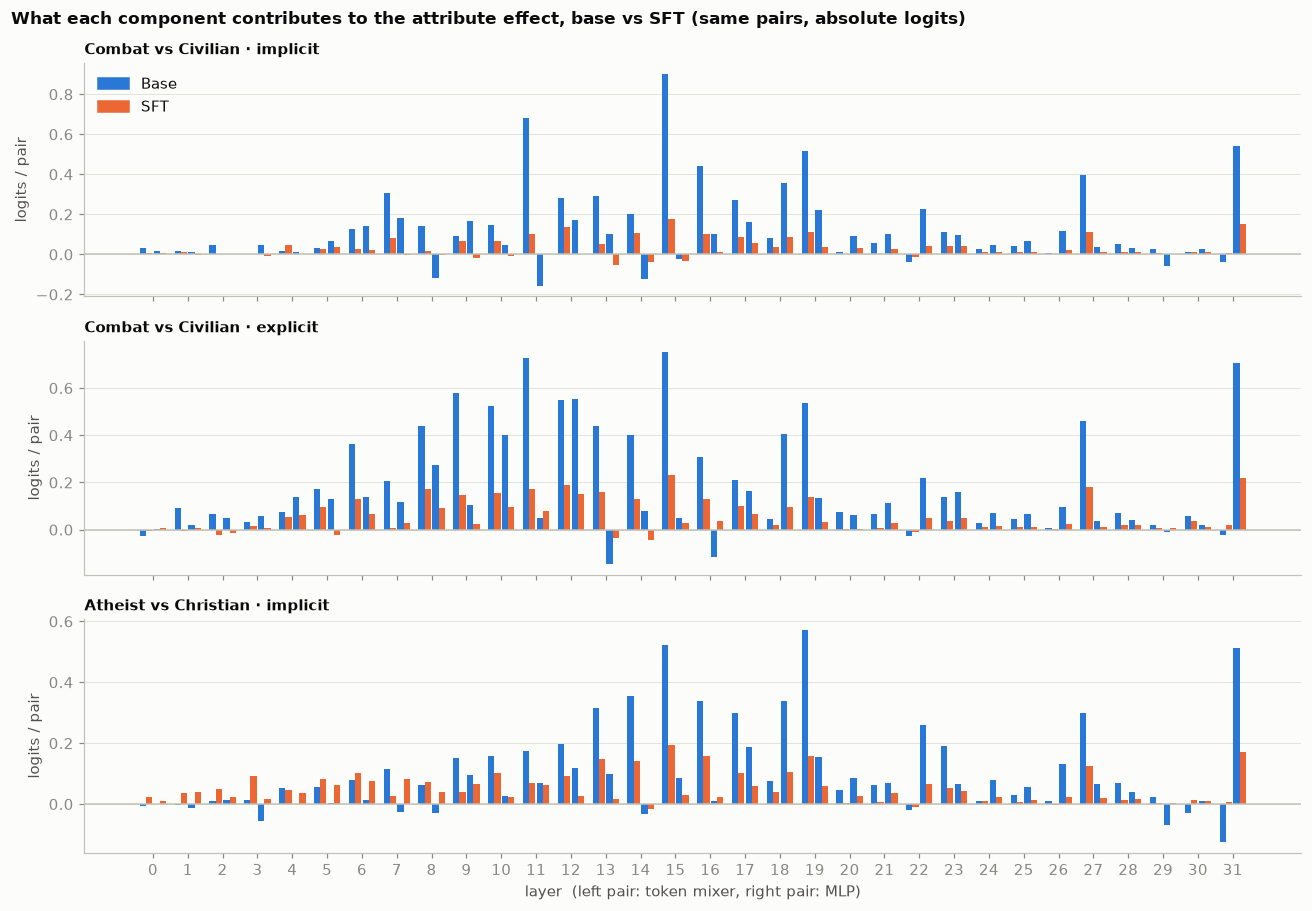

removed_logits_per_pair_base  \
contrast                        component                                     
Combat vs Civilian · implicit   attention L15                          0.90   
                                attention L11                          0.68   
Combat vs Civilian · explicit   attention L11                          0.73   
                                attention L15                          0.75   
                                MLP L31                                0.71   
                                GDN L9                                 0.58   
Atheist vs Christian · implicit attention L19                          0.57   
Combat vs Civilian · implicit   attention L19                          0.52   
Combat vs Civilian · explicit   MLP L12                                0.55   
                                attention L19                          0.54   
Combat vs Civilian · implicit   MLP L31                                0.54   
Combat vs Civilian · explicit   GDN L10                                0.52   
                                GDN L12                                0.55   
Atheist vs Christian · implicit MLP L31                                0.51   
Combat vs Civilian · implicit   GDN L16                                0.44   
Atheist vs Christian · implicit attention L15                          0.52   
Combat vs Civilian · implicit   attention L27                          0.40   
                                MLP L18                                0.35   
                                GDN L13                                0.29   
Atheist vs Christian · implicit MLP L18                                0.34   
                                GDN L14                                0.35   
                                GDN L17                                0.30   
                                MLP L22                                0.26   
                                GDN L16                                0.34   

                                               removed_logits_per_pair_sft  \
contrast                        component                                    
Combat vs Civilian · implicit   attention L15                         0.17   
                                attention L11                         0.10   
Combat vs Civilian · explicit   attention L11                         0.17   
                                attention L15                         0.23   
                                MLP L31                               0.22   
                                GDN L9                                0.15   
Atheist vs Christian · implicit attention L19                         0.16   
Combat vs Civilian · implicit   attention L19                         0.11   
Combat vs Civilian · explicit   MLP L12                               0.15   
                                attention L19                         0.14   
Combat vs Civilian · implicit   MLP L31                               0.15   
Combat vs Civilian · explicit   GDN L10                               0.15   
                                GDN L12                               0.19   
Atheist vs Christian · implicit MLP L31                               0.17   
Combat vs Civilian · implicit   GDN L16                               0.10   
Atheist vs Christian · implicit attention L15                         0.19   
Combat vs Civilian · implicit   attention L27                         0.11   
                                MLP L18                               0.09   
                                GDN L13                               0.05   
Atheist vs Christian · implicit MLP L18                               0.10   
                                GDN L14                               0.14   
                                GDN L17                               0.10   
                                MLP L22                               0.07   
                                GDN L16   

In [10]:
rows = []
for c in ["mil_combat_civ_impl", "mil_combat_civ_expl", "rel_atheist_christian_impl"]:
    b, s = RUNS.get(("base", "grid", c)), RUNS.get(("sft", "grid", c))
    if b is None or s is None: continue
    cb = components(b); cs = components(s)
    m = cb.merge(cs, on=["kind", "layer", "cls", "type"], suffixes=("_base", "_sft"))
    m["contrast"] = CONTRAST[c]
    rows.append(m)
cmp = pd.concat(rows) if rows else pd.DataFrame()
fig, axes = plt.subplots(len(rows), 1, figsize=(12, 2.8 * max(len(rows), 1)), sharex=True)
for ax, (c, d) in zip(np.atleast_1d(axes), cmp.groupby("contrast", sort=False)):
    for kind, off in (("mixer", -0.2), ("mlp", 0.2)):
        e = d[d.kind == kind].sort_values("layer")
        ax.bar(e.layer + off - 0.09, e.removed_logits_per_pair_base, width=0.18, color=SPEC_COLOR["base"])
        ax.bar(e.layer + off + 0.09, e.removed_logits_per_pair_sft, width=0.18, color=SPEC_COLOR["sft"])
    ax.axhline(0, color=AXIS, lw=1); ax.set_title(c, fontsize=10); ax.set_ylabel("logits / pair"); ax.grid(axis="x", visible=False)
np.atleast_1d(axes)[0].legend([plt.Rectangle((0, 0), 1, 1, color=SPEC_COLOR[s]) for s in ("base", "sft")], ["Base", "SFT"], loc="upper left")
np.atleast_1d(axes)[-1].set_xticks(range(32)); np.atleast_1d(axes)[-1].set_xlabel("layer  (left pair: token mixer, right pair: MLP)")
fig.suptitle("What each component contributes to the attribute effect, base vs SFT (same pairs, absolute logits)", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "base_vs_sft_components"); plt.show()

if len(cmp):
    cmp["change (logits)"] = cmp.removed_logits_per_pair_sft - cmp.removed_logits_per_pair_base
    view = cmp.assign(component=[f"{t} L{l}" if k == "mixer" else f"MLP L{l}" for k, l, t in zip(cmp.kind, cmp.layer, cmp.type)])
    table(view.sort_values("change (logits)").groupby("contrast", sort=False).head(8)
          [["contrast", "component", "removed_logits_per_pair_base", "removed_logits_per_pair_sft", "change (logits)", "share_removed_base", "share_removed_sft"]]
          .set_index(["contrast", "component"]), 2)

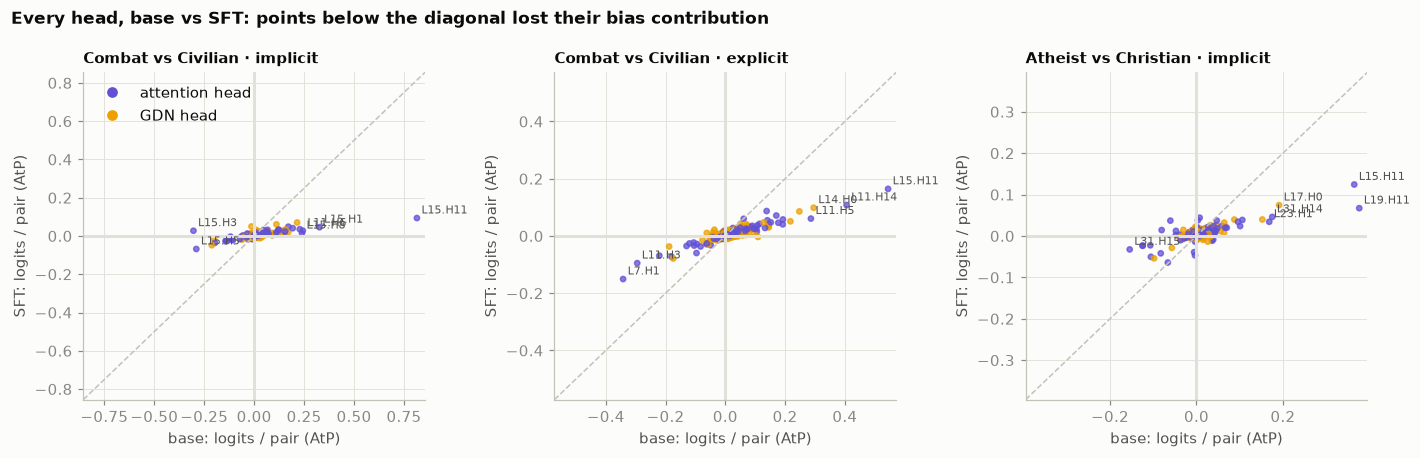

In [11]:
rows = []
for c in ["mil_combat_civ_impl", "mil_combat_civ_expl", "rel_atheist_christian_impl"]:
    b, s = RUNS.get(("base", "grid", c)), RUNS.get(("sft", "grid", c))
    if b is None or s is None: continue
    hb = b["atp"][(b["atp"].kind == "head_in") & (b["atp"].cls == "suffix")]
    hs = s["atp"][(s["atp"].kind == "head_in") & (s["atp"].cls == "suffix")]
    m = hb.merge(hs, on=["layer", "head"], suffixes=("_base", "_sft"))
    m["type"] = ["attention" if l in FULL_ATTN else "GDN" for l in m.layer]
    m["contrast"] = CONTRAST[c]; rows.append(m)
heads_cmp = pd.concat(rows) if rows else pd.DataFrame()
fig, axes = plt.subplots(1, max(len(rows), 1), figsize=(13, 4.2))
for ax, (c, d) in zip(np.atleast_1d(axes), heads_cmp.groupby("contrast", sort=False)):
    ax.scatter(d.removed_logits_per_pair_base, d.removed_logits_per_pair_sft, c=[TYPE_COLOR[t] for t in d.type], s=12, alpha=0.75)
    lim = np.abs(d[["removed_logits_per_pair_base", "removed_logits_per_pair_sft"]].values).max() * 1.05
    ax.plot([-lim, lim], [-lim, lim], color=AXIS, lw=1, ls="--"); ax.axhline(0, color=GRID); ax.axvline(0, color=GRID)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="base: logits / pair (AtP)", ylabel="SFT: logits / pair (AtP)")
    ax.set_title(c, fontsize=10)
    for _, x in d.reindex(d.removed_logits_per_pair_base.abs().sort_values(ascending=False).index).head(6).iterrows():
        ax.annotate(f"L{x['layer']}.H{x['head']}", (x.removed_logits_per_pair_base, x.removed_logits_per_pair_sft), fontsize=7.5, color=INK2,
                    xytext=(3, 3), textcoords="offset points")
np.atleast_1d(axes)[0].legend([plt.Line2D([], [], marker="o", ls="", color=TYPE_COLOR[t]) for t in ("attention", "GDN")], ["attention head", "GDN head"], loc="upper left")
fig.suptitle("Every head, base vs SFT: points below the diagonal lost their bias contribution", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "base_vs_sft_heads"); plt.show()

**Reading it:**

- **Same path, lower volume.** The decision tokens still receive the attribute at layers 15–20 under SFT. On Combat vs Civilian (implicit), the share reached by layer 18 is 0.74 (base) vs 0.69 (SFT). The relative component profile is preserved: r = 0.83–0.84. **SFT did not move the computation elsewhere; it shrank what flows through the existing circuit.**
- **The movers lose the most.**
  - On Combat vs Civilian (implicit), **L15.H11 keeps only 11%** of its contribution (0.81 → 0.09 logits per pair). Its share of the remaining effect drops from 61% to 27%.
  - Attention layers 11 and 15 keep 15% and 19%, against 28% for the late MLP-31 readout.
  - L15.H3, an opposing head in the base model, flips to a weak carrier.
- **GDN mixers keep the most; attention keeps less in every contrast.** By component type, attention keeps 22% / 28% / 41% of its contribution (implicit combat / explicit combat / religion), against 34% / 33% / 54% for GDN. SFT's LoRA does not modify GDN token mixers, so their smaller contribution can only come from smaller attribute signals arriving from upstream.
- **This matches the probe preview in the data notebook.** Under SFT the attribute largely disappears from the decision tokens in the middle layers. Patching shows *where*: at the attention movers of layers 11–19.

**What this does and does not show:**
- **Shown:** where the bias flows in the base model, and where SFT weakened it.
- **Not shown yet:**
  - *How* SFT weakened L15.H11: whether its attention to the attribute dropped (QK) or what it writes changed (OV/gate).
  - Whether the identified heads are *jointly* sufficient (circuit faithfulness).
  - These are the next experiments.

## Summary for the team

**The bias pathway in Qwen3.5-9B (English):**
```
attribute tokens ──(attention 7, 11 · GDN 9–14)──▶ CV / instruction tokens
                 ──(attention 15: H11, H1, H8 · attention 19: H11 · GDN 16–17: L17.H0)──▶ decision tokens  [layers 15–20]
                 ──(MLP 31 · attention 27/31: L27.H5, L31.H14)──▶ hire − reject
   opposing:  L15.H5, L15.H3, L17.H20, L23.H14, L31.H15
```

**What SFT does to it:**
- Same pathway, about 70% less signal.
- The biggest cut is at the layer-11/15 attention movers, L15.H11 above all (−89% on implicit combat).
- The untouched GDN layers shrink least.

**Next experiments:**
1. **Circuit faithfulness:** patch the identified heads jointly. Do they reproduce, or remove, the whole effect?
2. **QK vs OV/gate decomposition of L15.H11** in base vs SFT: did SFT change where the head looks, or what it writes?
3. **Adapter masking:** apply the SFT LoRA on attention layers 11/15/19 only. Is that enough for most of the debiasing?
4. **DPO:** the same runs on the DPO adapter once it arrives, and the per-token reward analysis for the shortcut question.
5. **Identity vs availability:** the hand-written minimal pairs, to test whether L15.H11 reads the identity words or the "looking for a civilian job" clause.